# NextCup · חקירת נתונים
אחרי קפה עם קפאין, האם דווח על עוד קפה באותו יום וכמה דקות עברו? שלבי הבדיקה הולכים לפי `eda_plan.md`.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

root = Path.cwd()
if not (root / "data/next_coffee_events.csv").exists():
    root = root.parent
sys.path.insert(0, str(root))
from analysis import LABEL, WAIT, FEATURES, baseline_scores, load_events

d = load_events()
d.info()
display(d.describe().round(2))

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True})
GREEN, ORANGE = "#236C55", "#AC603A"

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5623 entries, 0 to 5622
Data columns (total 18 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_id                   5623 non-null   int64  
 1   recall_day                  5623 non-null   int64  
 2   split                       5623 non-null   object 
 3   weekday                     5623 non-null   object 
 4   age_years                   5623 non-null   int64  
 5   sex                         5623 non-null   object 
 6   clock_time                  5623 non-null   object 
 7   minute_of_day               5623 non-null   int64  
 8   coffee_mg                   5623 non-null   float64
 9   event_caffeine_mg           5623 non-null   float64
 10  day_caffeine_mg_to_now      5623 non-null   float64
 11  prior_coffee_events         5623 non-null   int64  
 12  prior_caffeine_events       5623 non-null   int64  
 13  minutes_since_prior_coffee  1180 

,person_id,recall_day,age_years,minute_of_day,coffee_mg,event_caffeine_mg,day_caffeine_mg_to_now,prior_coffee_events,prior_caffeine_events,minutes_since_prior_coffee,same_minute_items,high_dose_flag,has_next_coffee,minutes_to_next_coffee
count,5623.00,5623.00,5623.00,5623.00,5623.00,5623.00,5623.00,5623.00,5623.00,1180.0,5623.00,5623.00,5623.00,1180.0
mean,98248.22,1.47,54.79,588.69,155.23,156.06,200.32,0.28,0.35,354.39,1.03,0.00,0.21,354.39
std,2703.47,0.50,16.54,247.96,188.85,189.11,228.93,0.63,0.73,226.85,0.16,0.07,0.41,226.85
min,93705.00,1.00,18.00,0.00,11.00,11.00,11.00,0.00,0.00,10.0,1.00,0.00,0.00,10.0
25%,95914.00,1.00,42.00,420.00,78.00,78.00,96.00,0.00,0.00,180.0,1.00,0.00,0.00,180.0
50%,98256.00,1.00,57.00,510.00,108.00,108.00,144.00,0.00,0.00,300.0,1.00,0.00,0.00,300.0
75%,100515.50,2.00,68.00,660.00,192.00,192.00,240.00,0.00,0.00,525.0,1.00,0.00,0.00,525.0
max,102956.00,2.00,80.00,1439.00,5040.00,5040.00,5040.00,8.00,8.00,1315.0,3.00,1.00,1.00,1315.0


## איכות הנתונים
חוסרים בפער הזמן הקודם מציינים קפה ראשון, וחוסרים בפער העתידי מציינים קפה אחרון. את הדיווחים הקיצוניים מסמנים כדי לבדוק רגישות בלי למחוק אירוע שתייה.

In [2]:
quality = pd.Series({
    "rows": len(d),
    "people": d.person_id.nunique(),
    "person_days": d.groupby(["person_id", "recall_day"]).ngroups,
    "duplicate_event_keys": d.duplicated(["person_id", "recall_day", "minute_of_day"]).sum(),
    "invalid_gaps": d[WAIT].dropna().le(0).sum(),
    "high_dose_flags": d.high_dose_flag.sum(),
    "on_half_hour_pct": 100 * d.minute_of_day.mod(30).eq(0).mean(),
})
display(quality.round(2), d.isna().sum().loc[lambda s: s.gt(0)])

rows                    5623.00
people                  2704.00
person_days             4443.00
duplicate_event_keys       0.00
invalid_gaps               0.00
high_dose_flags           26.00
on_half_hour_pct          91.84
dtype: float64

minutes_since_prior_coffee    4443
minutes_to_next_coffee        4443
dtype: int64

## התפלגויות
בכ־21% מהאירועים דווח עוד קפה. חציון ההמתנה במקרים האלה הוא חמש שעות.

has_next_coffee
לא    4443
כן    1180
Name: count, dtype: int64

,events,people
recall_day,,
1,2967,2362
2,2656,2081


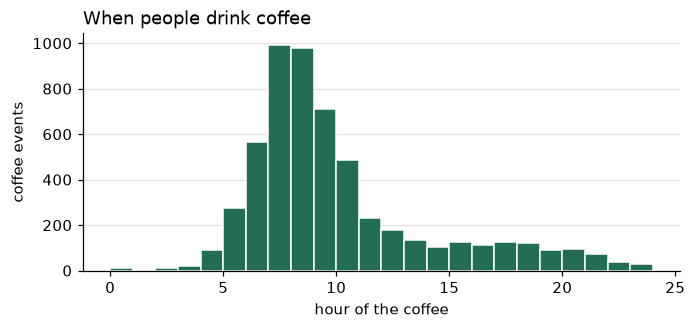

In [3]:
def bar_chart(values, edges, x_label, title, color=GREEN):
    fig, ax = plt.subplots(figsize=(7, 2.8))
    ax.hist(values.dropna(), bins=edges, color=color, edgecolor="white")
    ax.set_xlabel(x_label); ax.set_ylabel("coffee events"); ax.set_title(title, loc="left")
    ax.grid(axis="x", visible=False)
    plt.show()

display(d[LABEL].value_counts().rename(index={0: "לא", 1: "כן"}))
display(d.groupby("recall_day").agg(events=(LABEL, "size"), people=("person_id", "nunique")))
bar_chart(d.minute_of_day / 60, range(0, 25), "hour of the coffee", "When people drink coffee")

שעת השיא היא 07:00–07:59 עם 993 אירועים, ואחריה 08:00–08:59 עם 978 אירועים.

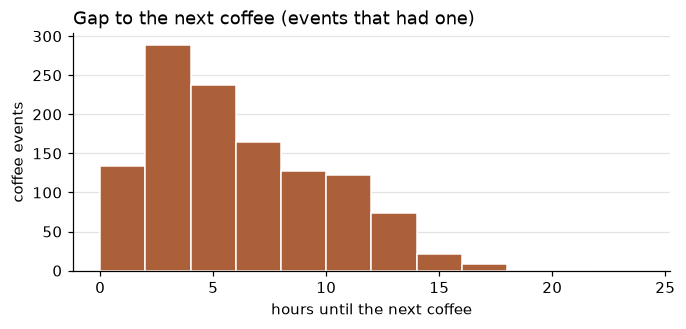

In [4]:
bar_chart(d[WAIT] / 60, range(0, 25, 2), "hours until the next coffee",
          "Gap to the next coffee (events that had one)", color=ORANGE)

כשדווח עוד קפה, הטווח השכיח ביותר היה 2 עד פחות מ־4 שעות, עם 289 אירועים מתוך 1,180.

## מה זז עם היעד
תווית ההמשך מושפעת גם מכמות הזמן שנותרה עד חצות. הוספנו את המכנים לכל השוואה. סימן המתאם מתאר את הכיוון ועוצמתו המדגמית בלבד.

In [5]:
def rate_by(group):
    return d.groupby(group)[LABEL].agg(events="size", positives="sum", rate="mean").round(3)

display(rate_by(d.minute_of_day.floordiv(120).mul(2).rename("start_hour")))
week = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]
display(rate_by("weekday").reindex(week))
display(d.groupby(LABEL)[["minute_of_day", "coffee_mg"]].median())
numeric = d[[*FEATURES, "age_years", LABEL, WAIT]].select_dtypes("number")
display(numeric.corr()[[LABEL, WAIT]].round(3))

,events,positives,rate
start_hour,,,
0,17,10,0.588
2,34,8,0.235
4,366,111,0.303
6,1559,380,0.244
8,1690,345,0.204
10,718,155,0.216
12,314,77,0.245
14,231,42,0.182
16,241,28,0.116


,events,positives,rate
weekday,,,
Sun,975,210,0.215
Mon,675,146,0.216
Tue,874,203,0.232
Wed,670,132,0.197
Thu,663,134,0.202
Fri,1072,226,0.211
Sat,694,129,0.186


,minute_of_day,coffee_mg
has_next_coffee,,
0,520.0,108.0
1,480.0,102.0


,has_next_coffee,minutes_to_next_coffee
minute_of_day,-0.134,-0.234
coffee_mg,-0.034,0.096
event_caffeine_mg,-0.035,0.096
day_caffeine_mg_to_now,-0.017,-0.100
prior_coffee_events,0.032,-0.247
prior_caffeine_events,-0.002,-0.252
minutes_since_prior_coffee,-0.270,-0.090
age_years,0.090,-0.119
has_next_coffee,1.000,NaN
minutes_to_next_coffee,NaN,1.000


שיעור הכוס הבאה נע בין 18.6% בשבת (129 מתוך 694) ל־23.2% בשלישי (203 מתוך 874). המתאם עם שעת הכוס היה ‎−0.13 בסיווג ו־‎−0.23 עם משך ההמתנה במקרים שבהם תועדה כוס נוספת.

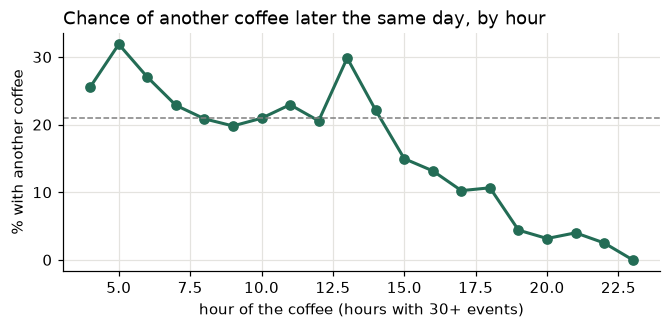

In [6]:
rate = d.groupby(d.minute_of_day // 60)[LABEL].agg(["mean", "size"])
rate = rate[rate["size"] >= 30]
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.plot(rate.index, rate["mean"] * 100, color=GREEN, marker="o", linewidth=2)
ax.axhline(d[LABEL].mean() * 100, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("hour of the coffee (hours with 30+ events)"); ax.set_ylabel("% with another coffee")
ax.set_title("Chance of another coffee later the same day, by hour", loc="left")
plt.show()

עד 14:00 בערך 20% עד 30% מכוסות הקפה מקבלות המשך באותו יום. מ־15:00 הסיכוי יורד בהדרגה, ואחרי 19:00 הוא מתחת ל־5%. זה הסיגנל הברור ביותר בנתונים, וחלק ממנו נובע מכך שהיום נגמר בחצות.

## עמודות מתואמות
הספירה של אירועי קפה מוקדמים קרובה לספירת כלל אירועי הקפאין. כמות הקפאין מהקפה הנוכחי כלולה במצטבר ולכן גם שם מתקבל מתאם גבוה. את ערך הוספת הפיצ'רים בודקים בתוך האימון.

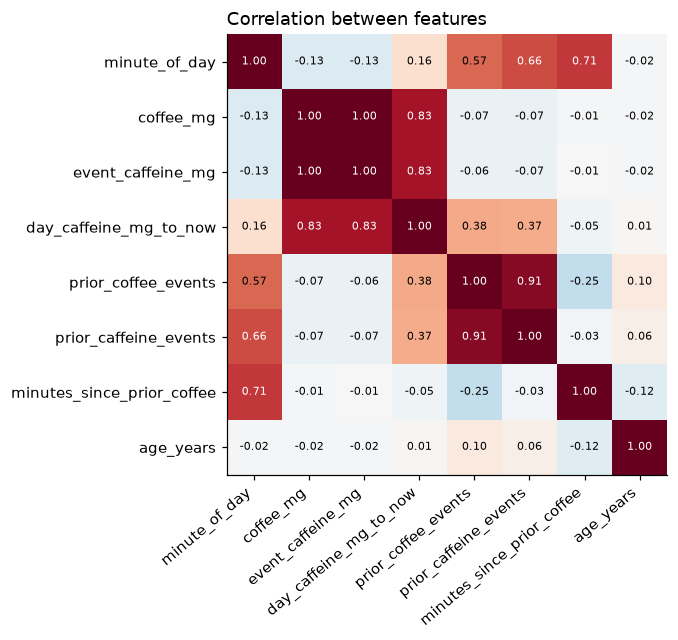

In [7]:
correlation = numeric.drop(columns=[LABEL, WAIT]).corr()
fig, ax = plt.subplots(figsize=(6.5, 5.2))
ax.imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation)), correlation.columns, rotation=40, ha="right")
ax.set_yticks(range(len(correlation)), correlation.columns)
ax.grid(False)
for i in range(len(correlation)):
    for j in range(len(correlation)):
        v = correlation.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 0.6 else "black")
ax.set_title("Correlation between features", loc="left")
plt.show()

שלושה זוגות כמעט מספרים את אותו סיפור: מ״ג הקפה ומ״ג הקפאין באותה דקה (‎~1.00, כי כמעט כל הקפאין באירוע מגיע מהקפה), ספירת הקפה הקודם מול ספירת הקפאין הקודם (0.91), ומ״ג הקפה מול המ״ג המצטבר (0.83). ב־M3 נשאיר שדה אחד מכל זוג, אלא אם השני משפר את התוצאה באימון.

## קווי הבסיס
החזאים הקבועים נקבעו באימון והטעות נמדדה במבחן לפי משתתף. רגרסיה מוגדרת רק בשורות עם קפה נוסף.

In [8]:
display(pd.Series(baseline_scores(d)))

majority                   0.000000
accuracy                   0.780749
median_minutes           300.000000
mae_minutes              184.475610
positive_test_events     246.000000
test_events             1122.000000
test_people              529.000000
dtype: float64

## מסקנה: יש סיגנל חלש
שעת השתייה והזמן מאז הקפה הקודם זזים עם התשובה (‎−0.13 ו־‎−0.27), ושאר העמודות כמעט לא. אין עמודה שמנבאת לבדה, ולכן צפוי שהמודל ב־M3 ישפר את קו הבסיס במידה מתונה בלבד. נשווה מודל שמתחיל בשעת השתייה לקו הבסיס (78.1% דיוק, MAE של 3.07 שעות), ואז נבדוק אם היסטוריית הקפה מוסיפה יכולת חיזוי על משתתפים נפרדים.